In [2]:
# Load and inspect LFW
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_lfw_people


lfw = fetch_lfw_people(
    min_faces_per_person=2,
    color=True,
    resize=0.5,
    download_if_missing=True
)

images = lfw.images
labels = lfw.target
identity_names = lfw.target_names

print(f"Images shape: {images.shape}")
print(f"Labels shape: {labels.shape}")
print(f"Number of identities: {len(identity_names)}")
print(f"Image dimensions: {images.shape[1]} × {images.shape[2]}")
print(f"Number of color channels: {images.shape[3]}")
print(f"Pixel-value range: {images.min():.3f} to {images.max():.3f}")

Images shape: (9164, 62, 47, 3)
Labels shape: (9164,)
Number of identities: 1680
Image dimensions: 62 × 47
Number of color channels: 3
Pixel-value range: 0.000 to 1.000


In [3]:
# Summarize the number of images per identity
images_per_identity = Counter(labels)

identity_statistics = pd.DataFrame({
    "identity_id": list(images_per_identity.keys()),
    "identity_name": [
        identity_names[identity_id]
        for identity_id in images_per_identity.keys()
    ],
    "image_count": list(images_per_identity.values())
}).sort_values(
    by="image_count",
    ascending=False
).reset_index(drop=True)

display(identity_statistics.head(10))

print(f"Total images: {len(images)}")
print(f"Total identities: {len(identity_names)}")
print(f"Minimum images per identity: {identity_statistics['image_count'].min()}")
print(f"Maximum images per identity: {identity_statistics['image_count'].max()}")
print(f"Median images per identity: {identity_statistics['image_count'].median()}")

,identity_id,identity_name,image_count
0,532,George W Bush,530
1,309,Colin Powell,236
2,1588,Tony Blair,144
3,392,Donald Rumsfeld,121
4,537,Gerhard Schroeder,109
5,111,Ariel Sharon,77
6,630,Hugo Chavez,71
7,856,Junichiro Koizumi,60
8,702,Jean Chretien,55
9,769,John Ashcroft,53


Total images: 9164
Total identities: 1680
Minimum images per identity: 2
Maximum images per identity: 530
Median images per identity: 3.0


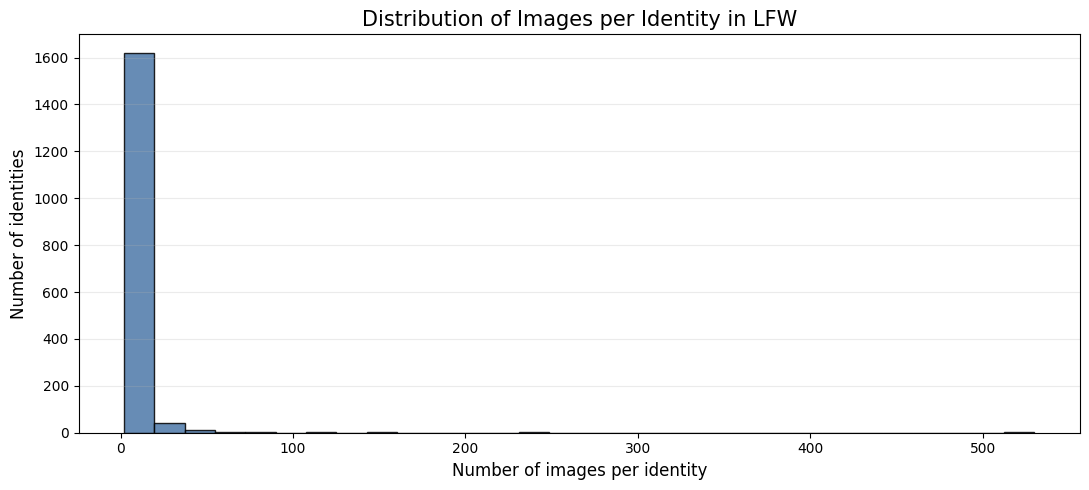

In [4]:
# Visualize the identity distribution
plt.figure(figsize=(11, 5))

plt.hist(
    identity_statistics["image_count"],
    bins=30,
    color="#4C78A8",
    edgecolor="black",
    alpha=0.85
)

plt.title("Distribution of Images per Identity in LFW", fontsize=15)
plt.xlabel("Number of images per identity", fontsize=12)
plt.ylabel("Number of identities", fontsize=12)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

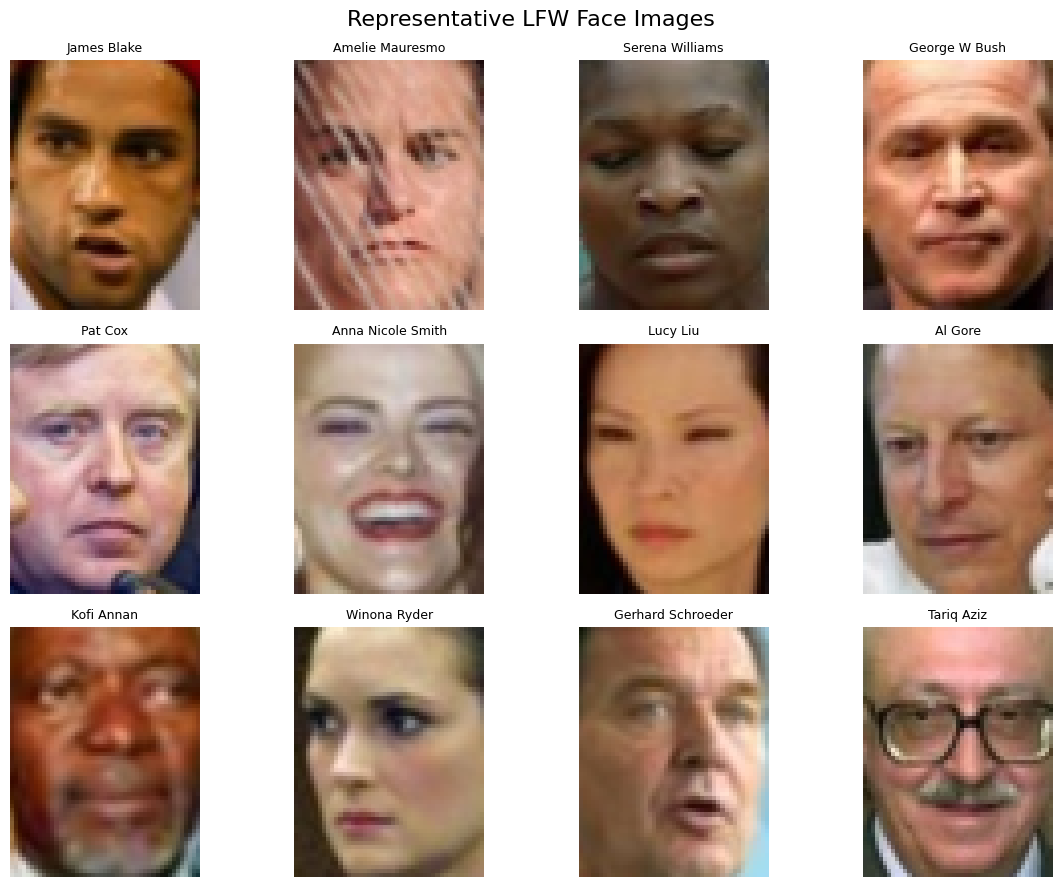

In [5]:
# Display representative face images

random_generator = np.random.default_rng(42)
sample_indices = random_generator.choice(
    len(images),
    size=12,
    replace=False
)

figure, axes = plt.subplots(3, 4, figsize=(12, 9))
axes = axes.ravel()

for axis, image_index in zip(axes, sample_indices):
    axis.imshow(images[image_index])
    axis.set_title(
        identity_names[labels[image_index]],
        fontsize=9
    )
    axis.axis("off")

figure.suptitle("Representative LFW Face Images", fontsize=16)
figure.tight_layout()
plt.show()

,minimum_images_required,eligible_identities
0,3,901
1,4,610
2,5,423
3,6,311
4,10,158


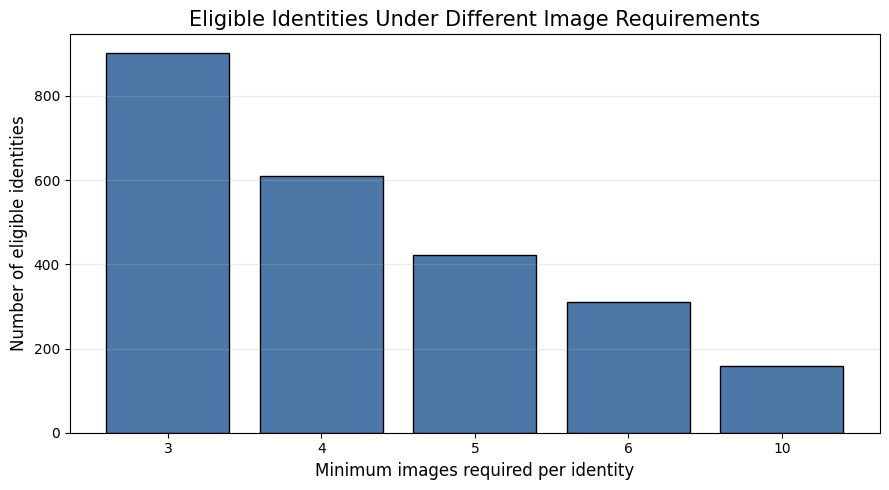

In [6]:
# Evaluate candidate gallery–probe configurations

minimum_images_per_identity = [3, 4, 5, 6, 10]

eligible_identity_counts = {
    minimum_images: (
        identity_statistics["image_count"] >= minimum_images
    ).sum()
    for minimum_images in minimum_images_per_identity
}

eligibility_summary = pd.DataFrame({
    "minimum_images_required": eligible_identity_counts.keys(),
    "eligible_identities": eligible_identity_counts.values()
})

display(eligibility_summary)

plt.figure(figsize=(9, 5))

plt.bar(
    eligibility_summary["minimum_images_required"].astype(str),
    eligibility_summary["eligible_identities"],
    color="#4C78A8",
    edgecolor="black"
)

plt.title("Eligible Identities Under Different Image Requirements", fontsize=15)
plt.xlabel("Minimum images required per identity", fontsize=12)
plt.ylabel("Number of eligible identities", fontsize=12)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()